<a href="https://colab.research.google.com/github/uday-andotra/WQU/blob/main/MScFE_622_SM_GWP2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 1


In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 6)

## Exporting data

In [ ]:
tickers = ["TLT", "GLD", "SPY", "^VIX"]

data = yf.download(
    tickers,
    start="2004-01-01",
    auto_adjust=True
)

prices = data["Close"]

prices.head()

[*********************100%***********************]  4 of 4 completed


Ticker,GLD,SPY,TLT,^VIX
Date,,,,
2004-01-02,NaN,73.644180,39.806252,18.219999
2004-01-05,NaN,74.445282,39.702518,17.490000
2004-01-06,NaN,74.518158,40.140953,16.730000
2004-01-07,NaN,74.769699,40.301239,15.500000
2004-01-08,NaN,75.067650,40.287086,15.610000


In [ ]:
prices.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5697 entries, 2004-01-02 to 2026-08-24
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   GLD     5474 non-null   float64
 1   SPY     5696 non-null   float64
 2   TLT     5696 non-null   float64
 3   ^VIX    5697 non-null   float64
dtypes: float64(4)
memory usage: 222.5 KB


In [ ]:
# Check Missing
prices.isna().sum()

,0
Ticker,
GLD,223
SPY,1
TLT,1
^VIX,0


In [ ]:
# Clean data
prices = prices.dropna()

prices.head()

Ticker,GLD,SPY,TLT,^VIX
Date,,,,
2004-11-18,44.380001,79.745255,43.650959,12.98
2004-11-19,44.779999,78.858780,43.302612,13.50
2004-11-22,44.950001,79.234863,43.528278,12.97
2004-11-23,44.750000,79.355736,43.582268,12.67
2004-11-24,45.049999,79.543831,43.582268,12.72


In [ ]:
print("Start date:", prices.index.min())
print("End date:", prices.index.max())
print("Number of observations:", len(prices))

Start date: 2004-11-18 00:00:00
End date: 2026-08-24 00:00:00
Number of observations: 5474


## Calulating Return

In [ ]:
# ETF Returns
etf_returns = np.log(
    prices[["TLT","GLD","SPY"]] /
    prices[["TLT","GLD","SPY"]].shift(1)
)

etf_returns = etf_returns.dropna()

etf_returns.head()

Ticker,TLT,GLD,SPY
Date,,,
2004-11-19,-0.008012,0.008973,-0.011179
2004-11-22,0.005198,0.003789,0.004758
2004-11-23,0.001240,-0.004459,0.001524
2004-11-24,0.000000,0.006682,0.002367
2004-11-26,-0.006550,0.005313,-0.000761


In [ ]:
# VIX Changes
vix_change = prices["^VIX"].diff()

vix_change = vix_change.dropna()

vix_change.head()

,^VIX
Date,
2004-11-19,0.520000
2004-11-22,-0.530000
2004-11-23,-0.300000
2004-11-24,0.050000
2004-11-26,0.059999


In [ ]:
# VIX Log Return
vix_return = np.log(
    prices["^VIX"] /
    prices["^VIX"].shift(1)
).dropna()
vix_return.head()

,^VIX
Date,
2004-11-19,0.039280
2004-11-22,-0.040051
2004-11-23,-0.023402
2004-11-24,0.003939
2004-11-26,0.004706


In [ ]:
# Dataset
dataset = pd.concat(
    [
        etf_returns,
        vix_change.rename("VIX_change")
    ],
    axis=1
)

dataset = dataset.dropna()

dataset.head()

,TLT,GLD,SPY,VIX_change
Date,,,,
2004-11-19,-0.008012,0.008973,-0.011179,0.520000
2004-11-22,0.005198,0.003789,0.004758,-0.530000
2004-11-23,0.001240,-0.004459,0.001524,-0.300000
2004-11-24,0.000000,0.006682,0.002367,0.050000
2004-11-26,-0.006550,0.005313,-0.000761,0.059999


## Cleaning and Visualization

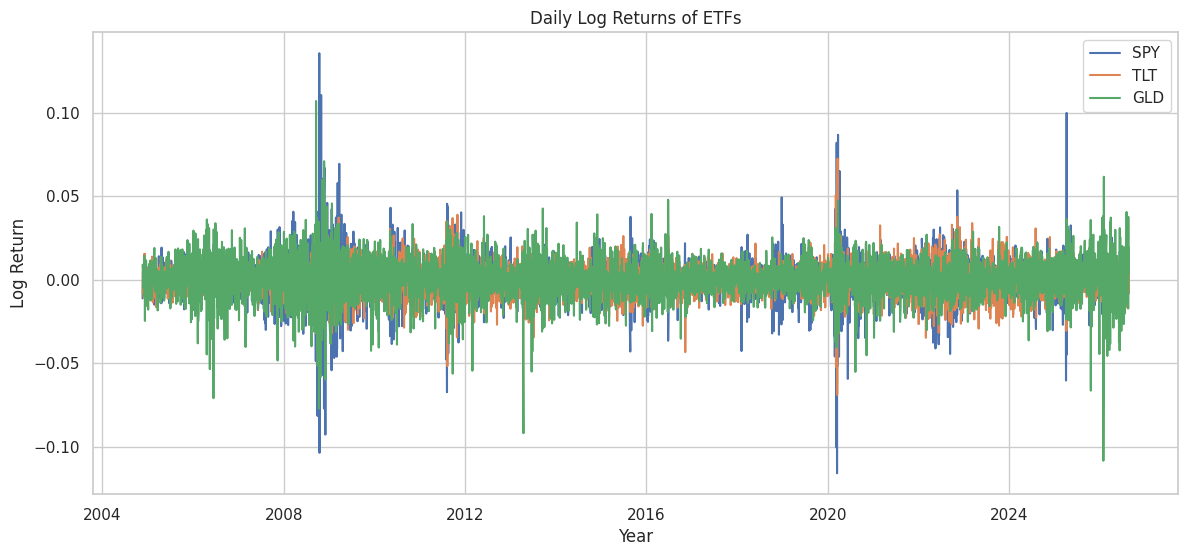

In [ ]:
# Plot 1: ETF Log Returns
plt.figure(figsize=(14,6))

plt.plot(
    dataset.index,
    dataset["SPY"],
    label="SPY"
)

plt.plot(
    dataset.index,
    dataset["TLT"],
    label="TLT"
)

plt.plot(
    dataset.index,
    dataset["GLD"],
    label="GLD"
)

plt.title(
    "Daily Log Returns of ETFs"
)

plt.xlabel("Year")
plt.ylabel("Log Return")

plt.legend()
plt.grid(True)

plt.show()

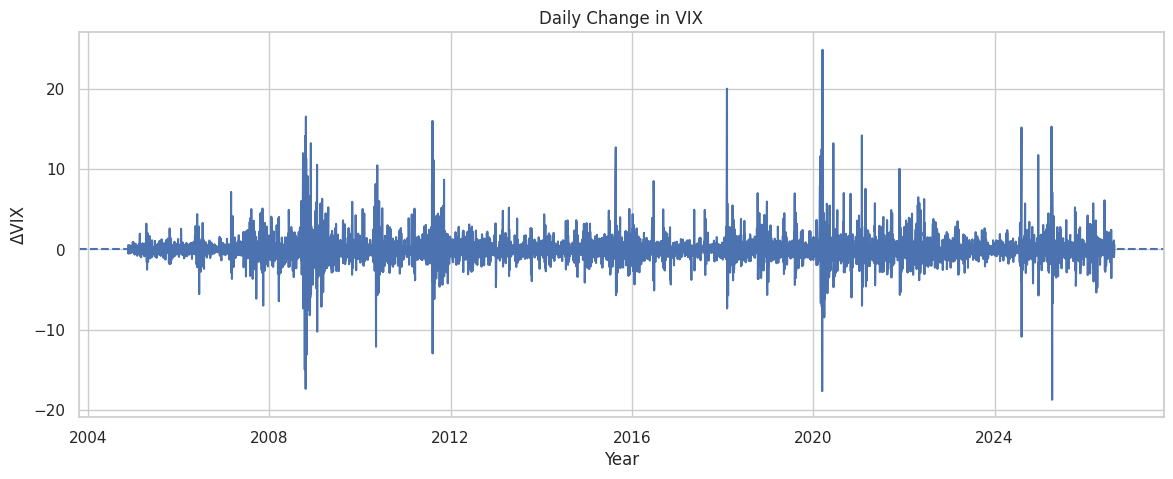

In [ ]:
# Plot 2: VIX Changes
plt.figure(figsize=(14,5))

plt.plot(
    dataset.index,
    dataset["VIX_change"]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title(
    "Daily Change in VIX"
)

plt.xlabel("Year")
plt.ylabel("ΔVIX")

plt.grid(True)

plt.show()

# Step 2

## Discrete Markov Chain Option

In [ ]:
vix = dataset["VIX_change"]

In [ ]:
q1 = vix.quantile(0.33)
q2 = vix.quantile(0.66)

print("Low threshold:", q1)
print("High threshold:", q2)

Low threshold: -0.4799995422363281
High threshold: 0.2800006866455078


In [ ]:
# Discretize dVIX into 3 regimes: Low, Medium, High
def classify_vix(x):

    if x <= q1:
        return 0

    elif x <= q2:
        return 1

    else:
        return 2


dataset["VIX_state"] = dataset["VIX_change"].apply(classify_vix)

dataset.head()

,TLT,GLD,SPY,VIX_change,VIX_state
Date,,,,,
2004-11-19,-0.008012,0.008973,-0.011179,0.520000,2
2004-11-22,0.005198,0.003789,0.004758,-0.530000,0
2004-11-23,0.001240,-0.004459,0.001524,-0.300000,1
2004-11-24,0.000000,0.006682,0.002367,0.050000,1
2004-11-26,-0.006550,0.005313,-0.000761,0.059999,1


In [ ]:
# Transition Matrix
states = dataset["VIX_state"].values

transition_matrix = pd.crosstab(
    states[:-1],
    states[1:],
    normalize="index"
)

transition_matrix.index = [
    "Low volatility",
    "Medium volatility",
    "High volatility"
]

transition_matrix.columns = [
    "Low volatility",
    "Medium volatility",
    "High volatility"
]

transition_matrix

,Low volatility,Medium volatility,High volatility
Low volatility,0.346748,0.296582,0.356670
Medium volatility,0.232816,0.424612,0.342572
High volatility,0.412621,0.269687,0.317691


In [ ]:
P = transition_matrix.values

eigenvalues, eigenvectors = np.linalg.eig(P.T)

stationary = eigenvectors[:,np.isclose(eigenvalues,1)]

stationary = stationary[:,0]

stationary = stationary / stationary.sum()

stationary

array([0.33150585, 0.32967836, 0.33881579])

In [ ]:
# Stationary Distribution
stationary_distribution = pd.DataFrame(
    stationary,
    index=[
        "Low volatility",
        "Medium volatility",
        "High volatility"
    ],
    columns=["Probability"]
)

stationary_distribution

,Probability
Low volatility,0.331506
Medium volatility,0.329678
High volatility,0.338816


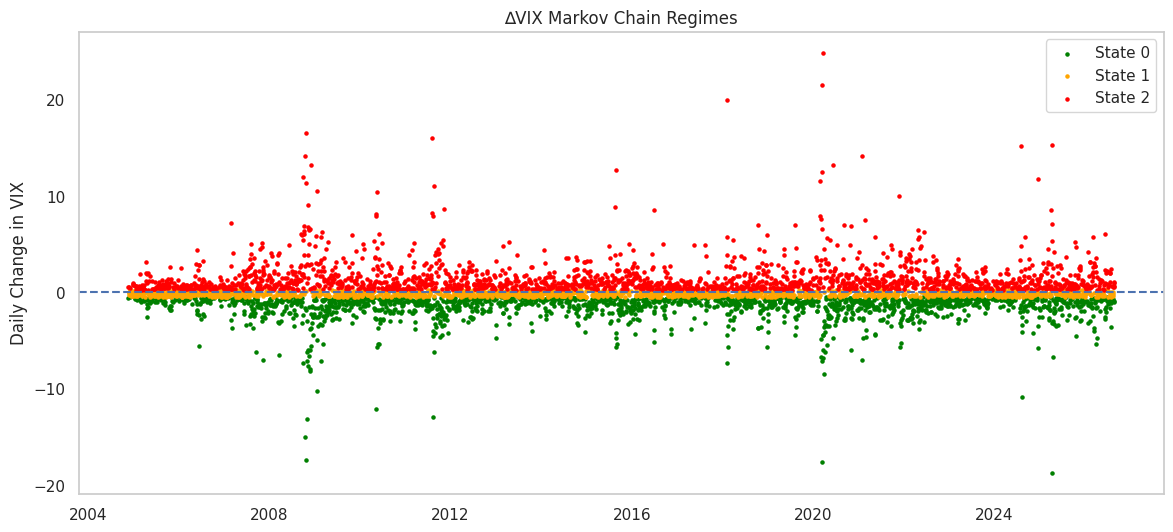

In [ ]:
# Plot Markov Regimes

plt.figure(figsize=(14,6))


colors = {
    0:"green",
    1:"orange",
    2:"red"
}


for state,color in colors.items():

    subset = dataset[
        dataset["VIX_state"]==state
    ]

    plt.scatter(
        subset.index,
        subset["VIX_change"],
        s=5,
        label=f"State {state}",
        color=color
    )


plt.axhline(0, linestyle="--")

plt.title("∆VIX Markov Chain Regimes")

plt.ylabel("Daily Change in VIX")

plt.legend()

plt.grid()

plt.show()

## Hidden Markov Model Option

In [ ]:
pip install hmmlearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 5.7 MB/s eta 0:00:00


In [ ]:
from hmmlearn.hmm import GaussianHMM


X = dataset[["VIX_change"]].values

In [ ]:
# Fit 2-state HMM
hmm_2 = GaussianHMM(
    n_components=2,
    covariance_type="full",
    n_iter=200,
    random_state=42
)


hmm_2.fit(X)
print("Means:")
print(hmm_2.means_)

print("Variances:")
print(hmm_2.covars_)

print("Transition Matrix:")
print(hmm_2.transmat_)

Means:
[[ 0.21292972]
 [-0.0741954 ]]
Variances:
[[[11.95905451]]

 [[ 0.65583795]]]
Transition Matrix:
[[0.88269822 0.11730178]
 [0.04125869 0.95874131]]


In [ ]:
# Fit 3-state HMM
hmm_3 = GaussianHMM(
    n_components=3,
    covariance_type="full",
    n_iter=200,
    random_state=42
)


hmm_3.fit(X)
print(
    "State Means:"
)

print(hmm_3.means_)


print(
    "Transition Matrix:"
)

print(hmm_3.transmat_)

State Means:
[[-0.01349224]
 [ 0.65552838]
 [-0.06123401]]
Transition Matrix:
[[9.10478219e-01 1.56722981e-02 7.38494831e-02]
 [1.28549972e-01 8.71450028e-01 2.81210645e-11]
 [5.85118390e-02 1.60553999e-03 9.39882621e-01]]


In [ ]:
# Most Likely States
hidden_states = hmm_3.predict(X)

dataset["HMM_state"] = hidden_states

In [ ]:
# Smoothed Probabilities
state_probabilities = hmm_3.predict_proba(X)

state_probabilities[:5]

array([[3.34888608e-089, 3.93659918e-129, 1.00000000e+000],
       [3.42324195e-003, 1.59900374e-006, 9.96575159e-001],
       [4.07289978e-003, 1.81084836e-006, 9.95925289e-001],
       [4.26632402e-003, 2.01323788e-006, 9.95731663e-001],
       [4.70856064e-003, 2.48904572e-006, 9.95288950e-001]])

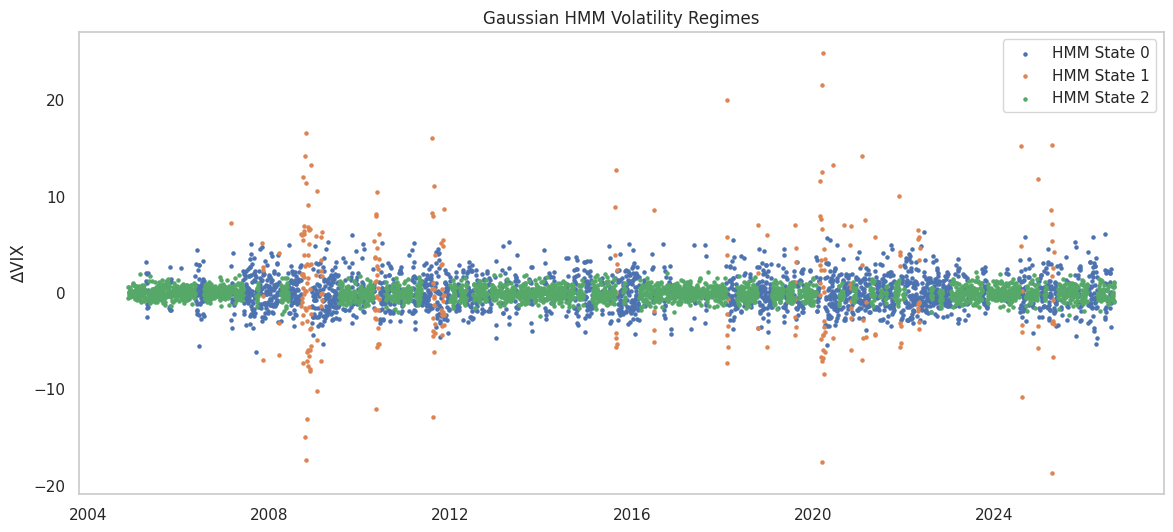

In [ ]:
#Plot HMM Regimes
plt.figure(figsize=(14,6))


for state in range(3):

    subset = dataset[
        dataset["HMM_state"]==state
    ]

    plt.scatter(
        subset.index,
        subset["VIX_change"],
        s=5,
        label=f"HMM State {state}"
    )


plt.title(
    "Gaussian HMM Volatility Regimes"
)

plt.ylabel(
    "∆VIX"
)

plt.legend()

plt.grid()

plt.show()

# Step 3

## log-likelihood, AIC and BIC

In [ ]:
def hmm_information_criteria(model, X):
    n = len(X)
    k = model.n_components

    n_parameters = (
        k * (k - 1) +  # transition probabilities
        (k - 1) +      # initial probabilities
        k +            # means
        k              # variances
    )

    loglik = model.score(X)

    AIC = 2 * n_parameters - 2 * loglik

    BIC = (
        np.log(n) * n_parameters
        - 2 * loglik
    )

    return loglik, n_parameters, AIC, BIC

In [ ]:
results = []

for name, model in [
    ("HMM-2", hmm_2),
    ("HMM-3", hmm_3)
]:

    loglik, n_params, aic, bic = hmm_information_criteria(
        model,
        X
    )

    results.append({
        "Model": name,
        "States": model.n_components,
        "Parameters": n_params,
        "Log-Likelihood": loglik,
        "AIC": aic,
        "BIC": bic
    })

model_comparison = pd.DataFrame(results)

model_comparison

,Model,States,Parameters,Log-Likelihood,AIC,BIC
0,HMM-2,2,7,-9319.903706,18653.807413,18700.060488
1,HMM-3,3,14,-8972.570369,17973.140738,18065.646889


## Mean, Standard deviation

In [ ]:
#Transition matrix
print("2-State HMM transition matrix:")
print(hmm_2.transmat_)

print("\n3-State HMM transition matrix:")
print(hmm_3.transmat_)

2-State HMM transition matrix:
[[0.88269822 0.11730178]
 [0.04125869 0.95874131]]

3-State HMM transition matrix:
[[9.10478219e-01 1.56722981e-02 7.38494831e-02]
 [1.28549972e-01 8.71450028e-01 2.81210645e-11]
 [5.85118390e-02 1.60553999e-03 9.39882621e-01]]


From the above results we made the decision to choose HMM-3 model

In [ ]:
dataset

,TLT,GLD,SPY,VIX_change,VIX_state,HMM_state
Date,,,,,,
2004-11-19,-0.008013,0.008973,-0.011179,0.520000,2,2
2004-11-22,0.005198,0.003789,0.004757,-0.530000,0,2
2004-11-23,0.001239,-0.004459,0.001525,-0.300000,1,2
2004-11-24,0.000000,0.006682,0.002367,0.050000,1,2
2004-11-26,-0.006550,0.005313,-0.000761,0.059999,1,2
...,...,...,...,...,...,...
2026-08-18,0.003804,-0.017263,-0.006779,0.650001,2,2
2026-08-19,0.016517,0.037646,0.002096,-0.950000,0,2
2026-08-20,-0.008225,0.003425,-0.008435,1.120000,2,2


In [ ]:
state_return_mean = dataset.groupby("HMM_state")[
    ["TLT", "GLD", "SPY"]
].mean()

state_return_std = dataset.groupby("HMM_state")[
    ["TLT", "GLD", "SPY"]
].std()

In [ ]:
print("Mean returns by state:")
print(state_return_mean)

print("\nStandard deviation by state:")
print(state_return_std)

Mean returns by state:
                TLT       GLD       SPY
HMM_state                              
0          0.000269  0.000355 -0.000023
1          0.001648  0.000245 -0.005401
2         -0.000153  0.000475  0.001321

Standard deviation by state:
                TLT       GLD       SPY
HMM_state                              
0          0.009581  0.012284  0.012288
1          0.017640  0.020341  0.034173
2          0.007438  0.009525  0.005605


In [ ]:
# Combine
state_summary = pd.concat(
    {
        "Mean Return": state_return_mean,
        "Std Return": state_return_std
    },
    axis=1
)

state_summary

Mean Return                     Std Return                    
                  TLT       GLD       SPY        TLT       GLD       SPY
HMM_state                                                               
0            0.000269  0.000355 -0.000023   0.009581  0.012284  0.012288
1            0.001648  0.000245 -0.005401   0.017640  0.020341  0.034173
2           -0.000153  0.000475  0.001321   0.007438  0.009525  0.005605

In [ ]:
# Rename state by Regime State
hmm_means = hmm_3.means_.flatten()

ordered_states = np.argsort(hmm_means)

state_name_mapping = {
    ordered_states[0]: "Calm",
    ordered_states[1]: "Normal",
    ordered_states[2]: "Stress"
}

dataset["Regime"] = dataset["HMM_state"].map(state_name_mapping)
state_return_mean_named = dataset.groupby("Regime")[
    ["TLT", "GLD", "SPY"]
].mean()

state_return_std_named = dataset.groupby("Regime")[
    ["TLT", "GLD", "SPY"]
].std()

print(state_return_mean_named)
print(state_return_std_named)

             TLT       GLD       SPY
Regime                              
Calm   -0.000153  0.000475  0.001321
Normal  0.000269  0.000355 -0.000023
Stress  0.001648  0.000245 -0.005401
             TLT       GLD       SPY
Regime                              
Calm    0.007438  0.009525  0.005605
Normal  0.009581  0.012284  0.012288
Stress  0.017640  0.020341  0.034173


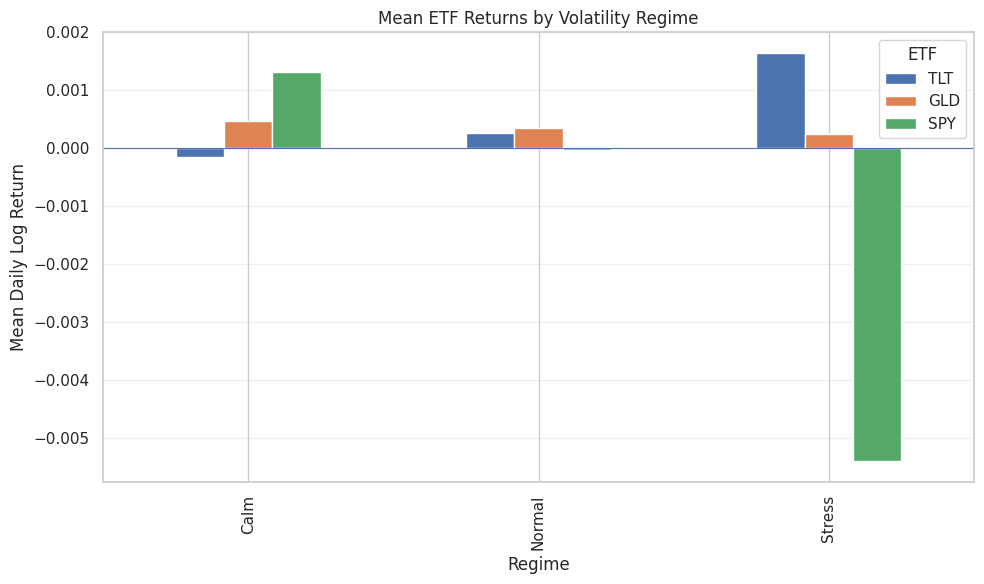

In [ ]:
# Visualization
state_return_mean_named.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.axhline(0, linewidth=0.8)

plt.title("Mean ETF Returns by Volatility Regime")
plt.xlabel("Regime")
plt.ylabel("Mean Daily Log Return")
plt.legend(title="ETF")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Step 4: Designing the Rotation Strategy

**Decision rule** (taken directly from the mean-return table computed in Step 3):

| State  | Highest-mean ETF | Allocation     |
|--------|------------------|----------------|
| Calm   | SPY              | 100 % SPY      |
| Normal | GLD              | 100 % GLD      |
| Stress | TLT              | 100 % TLT      |

**Justification**  
Allocate 100 % of the portfolio to the single ETF that historically recorded the highest average daily log-return in that regime. A one-day execution lag is applied in the back-test so that the regime observed at the close of day *t* determines the position held on day *t*+1, eliminating look-ahead bias.

# Step 5: Backtesting and Evaluation

State counts from dataset['Regime']:
Regime
Calm      2889
Normal    2306
Stress     278
Name: count, dtype: int64

=== Performance Summary ===
                        Cumulative Return  Annualized Return  Volatility  \
Regime Rotation                   25.0959             0.1624      0.1554   
Equal-Weight (monthly)             4.0420             0.0793      0.0981   
Buy & Hold SPY                     5.5693             0.1046      0.1889   

                        Sharpe Ratio  Max Drawdown  
Regime Rotation               1.0451       -0.2709  
Equal-Weight (monthly)        0.8084       -0.2399  
Buy & Hold SPY                0.5538       -0.5958  


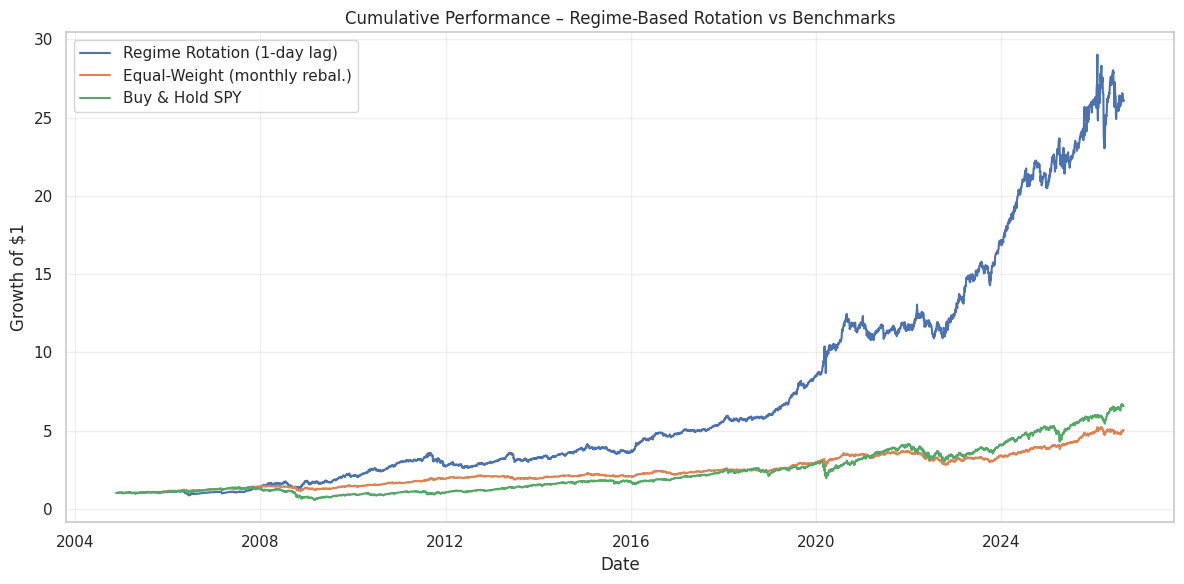

In [ ]:
# ------------------------------------------------------------------
# Step 5 – Back-test with 1-day lag
# ------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Confirm the labelled states
print("State counts from dataset['Regime']:")
print(dataset["Regime"].value_counts())

# 2. Decision rule (from your Step-3 mean table)
state_to_asset = {
    "Calm"  : "SPY",
    "Normal": "GLD",
    "Stress": "TLT"
}

# 3. 1-day execution lag
lagged_state   = dataset["Regime"].shift(1)
strategy_asset = lagged_state.map(state_to_asset)

# 4. Build strategy returns
mask = strategy_asset.notna()

# Create an empty Series with the correct index
strategy_ret = pd.Series(index=etf_returns.index[mask], dtype=float, name="RegimeRotation")

for date, asset in strategy_asset.loc[mask].items():
    strategy_ret.loc[date] = etf_returns.loc[date, asset]

# 5. Benchmarks
dates = strategy_ret.index
spy_bh = etf_returns.loc[dates, "SPY"]

# Equal-weight, monthly rebalanced
eq = etf_returns.loc[dates, ["TLT", "GLD", "SPY"]].copy()
weights = pd.DataFrame(1/3, index=dates, columns=eq.columns)

# Rebalance at month-ends
month_ends = eq.resample("ME").last().index
for dt in month_ends:
    if dt in weights.index:
        weights.loc[dt:] = 1/3

eq_ret = (eq * weights).sum(axis=1)

# 6. Performance metrics
def perf_stats(r, name):
    r = r.dropna()
    cum     = (1 + r).cumprod().iloc[-1] - 1
    ann_ret = r.mean() * 252
    ann_vol = r.std() * np.sqrt(252)
    sharpe  = ann_ret / ann_vol if ann_vol > 0 else np.nan
    max_dd  = ((1 + r).cumprod() / (1 + r).cumprod().cummax() - 1).min()
    return pd.Series({
        "Cumulative Return": cum,
        "Annualized Return": ann_ret,
        "Volatility"       : ann_vol,
        "Sharpe Ratio"     : sharpe,
        "Max Drawdown"     : max_dd
    }, name=name)

stats = pd.concat([
    perf_stats(strategy_ret, "Regime Rotation"),
    perf_stats(eq_ret,       "Equal-Weight (monthly)"),
    perf_stats(spy_bh,       "Buy & Hold SPY")
], axis=1).T.round(4)

print("\n=== Performance Summary ===")
print(stats)

# 7. Cumulative performance plot
plt.figure(figsize=(12, 6))
plt.plot((1 + strategy_ret).cumprod(), label="Regime Rotation (1-day lag)")
plt.plot((1 + eq_ret).cumprod(),       label="Equal-Weight (monthly rebal.)")
plt.plot((1 + spy_bh).cumprod(),       label="Buy & Hold SPY")
plt.title("Cumulative Performance – Regime-Based Rotation vs Benchmarks")
plt.ylabel("Growth of $1")
plt.xlabel("Date")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()